In [72]:
import pandas as pd

In [73]:
url  = "/home/mdrafsunsheikh/Desktop/QS_university_ranking_app/Datasets/2024_QS_World_University_Rankings.csv"
df = pd.read_csv(url)

In [74]:
df.head()

,2024 QS World University Rankings,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28
0,2024,2023,Institution Name,Location,NaN,Classification,NaN,NaN,NaN,NaN,...,NaN,International Students,NaN,International Research Network,NaN,Employment Outcomes,NaN,Sustainability,NaN,Overall
1,RANK,RANK,NaN,NaN,Location,SIZE,FOCUS,RES.,AGE,STATUS,...,RANK,SCORE,RANK,SCORE,RANK,SCORE,RANK,Score,Rank,SCORE
2,rank display,rank display2,institution,location code,location,size,focus,research,age band,status,...,ifr rank,isr score,isr rank,irn score,irn rank,ger score,ger rank,SUS SCORE,SUS RANK,Overall Score
3,1,1,Massachusetts Institute of Technology (MIT),US,United States,M,CO,VH,5,B,...,56,88.2,128,94.3,58,100,4,95.2,51,100.0
4,2,2,University of Cambridge,UK,United Kingdom,L,FC,VH,5,A,...,64,95.8,85,99.9,7,100,6,97.3,33=,99.2


In [75]:
dataset = df[["Unnamed: 12", "Unnamed: 13"]]
dataset.head()

,Unnamed: 12,Unnamed: 13
0,Employer Reputation,NaN
1,SCORE,RANK
2,er score,er rank
3,100.0,2
4,100.0,4


In [76]:
dataset.shape

(1500, 2)

In [77]:
dataset.isna().sum()

Unnamed: 12    1
Unnamed: 13    2
dtype: int64

In [78]:
dataset = dataset.dropna()

In [79]:
dataset.isna().sum()

Unnamed: 12    0
Unnamed: 13    0
dtype: int64

In [80]:
dataset.shape

(1498, 2)

In [81]:
dataset.head()

,Unnamed: 12,Unnamed: 13
1,SCORE,RANK
2,er score,er rank
3,100.0,2
4,100.0,4
5,100.0,5


In [82]:
new_df = dataset.iloc[3:].copy()

In [83]:
new_df.head()

,Unnamed: 12,Unnamed: 13
4,100.0,4
5,100.0,5
6,100.0,1
7,100.0,3
8,99.4,12


In [84]:
new_df.reset_index(drop=True, inplace=True)

In [85]:
new_df = new_df.dropna()
new_df.isna().sum()

Unnamed: 12    0
Unnamed: 13    0
dtype: int64

In [86]:
new_df['Unnamed: 12'] = pd.to_numeric(new_df['Unnamed: 12'], errors='coerce', downcast='float')
new_df['Unnamed: 13'] = pd.to_numeric(new_df['Unnamed: 13'], errors='coerce', downcast='float')
new_df = new_df.dropna()
new_df.isna().sum()

Unnamed: 12    0
Unnamed: 13    0
dtype: int64

In [87]:
X = new_df.drop("Unnamed: 13", axis = 1)
y = new_df["Unnamed: 13"]

In [88]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 599 entries, 0 to 1337
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 12  599 non-null    float32
dtypes: float32(1)
memory usage: 7.0 KB


In [89]:
y.info()

<class 'pandas.core.series.Series'>
Index: 599 entries, 0 to 1337
Series name: Unnamed: 13
Non-Null Count  Dtype  
--------------  -----  
599 non-null    float32
dtypes: float32(1)
memory usage: 7.0 KB


In [90]:
y.isna().sum()

0

In [91]:
X.head()

,Unnamed: 12
0,100.000000
1,100.000000
2,100.000000
3,100.000000
4,99.400002


In [92]:
y.isnull().sum()

0

<Axes: >

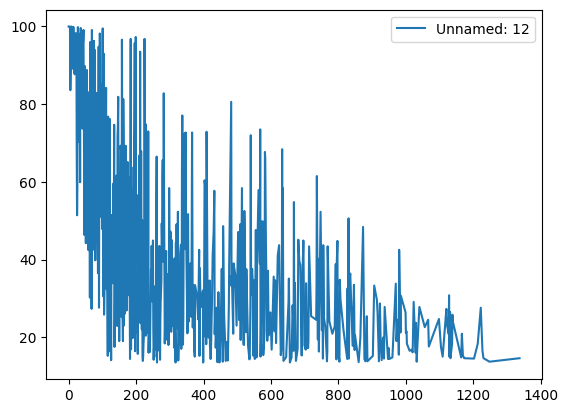

In [93]:
import matplotlib as plt
X.plot()

### **Train Using Random Forest**

In [94]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
random_forest_reg = RandomForestRegressor(random_state=0)
random_forest_reg.fit(X, y.values)

RandomForestRegressor(random_state=0)

In [95]:
y_pred = random_forest_reg.predict(X)
error = np.sqrt(mean_squared_error(y, y_pred))
print(error)

0.7635114440524807


In [ ]:
pred = np.array([[26.9]])
print(int(random_forest_reg.predict(pred)))